# Olist E-Commerce: Cohort & Retention Analysis
**Notebook 2: Cohort analysis built on the star schema**

**Business question:** Are customers acquired in 2017 still buying in 2018?

Data comes from the SQLite star schema built in notebook 1 (`data/processed/olist_star.db`), not from the raw CSVs.

## 1. Setup
Define project paths and confirm the star schema database exists.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
DB_PATH = PROJECT_ROOT / "data" / "processed" / "olist_star.db"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

print("Project root:", PROJECT_ROOT)
print("Database found:", DB_PATH.exists())

with sqlite3.connect(DB_PATH) as con:
    tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con)
print(tables)

Project root: c:\Users\HP\Desktop\Toluwalase Aderemi\Career\Programs_or_Jobs\Elevvo\Business_insights_olist
Database found: True
            name
0  dim_customers
1       dim_date
2    fact_orders
3  fact_payments
4   fact_reviews


## 2. Load Delivered Orders from the Star Schema
One star join: each delivered order with its customer's cohort month (from `dim_customers`) and the order's year and month (from `dim_date`). Then compute the month offset and apply the Jan 2017 to Aug 2018 cohort window. The numbers must match the raw-data analysis exactly.

In [2]:
query = """
SELECT o.order_id, c.customer_unique_id, c.cohort_month, d.year, d.month
FROM fact_orders o
JOIN dim_customers c ON o.customer_key = c.customer_key
JOIN dim_date d      ON o.order_date_key = d.date_key
WHERE o.order_status = 'delivered';
"""
with sqlite3.connect(DB_PATH) as con:
    df = pd.read_sql(query, con)

cohort_year = df.cohort_month.str[:4].astype(int)
cohort_mon  = df.cohort_month.str[5:7].astype(int)
df["month_offset"] = (df.year - cohort_year) * 12 + (df.month - cohort_mon)

purchases = df[df.cohort_month.between("2017-01", "2018-08")].copy()

print("Delivered orders:", len(df), "| in window:", len(purchases))
print("Customers in window:", purchases.customer_unique_id.nunique(), "\n")
print(purchases.month_offset.value_counts().sort_index())

Delivered orders: 96478 | in window: 96200
Customers in window: 93094 

month_offset
0     94312
1       432
2       283
3       202
4       181
5       149
6       132
7       103
8        88
9        62
10       75
11       58
12       36
13       26
14       25
15       17
16        9
17        9
19        1
Name: count, dtype: int64


### Validation: star schema vs raw data
Rebuilding the cohort inputs from the SQLite star schema reproduces the raw-data analysis **exactly**: 96,478 delivered orders, 96,200 in the Jan 2017 to Aug 2018 window, 93,094 customers, and identical order counts at every month offset (e.g. Month 0: 94,312; Month 1: 432). The model preserves the information needed for cohort analysis.

## 3. Retention Matrix (from the star schema)
Count distinct customers per cohort and month offset, divide by cohort size, and compare against the matrix saved from the raw-data analysis (`retention_from_raw.csv`).

In [3]:
import numpy as np

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

counts = (purchases.groupby(["cohort_month", "month_offset"])
          .customer_unique_id.nunique().unstack()
          .reindex(columns=range(0, 20)))

for cohort in counts.index:
    max_offset = (pd.Period("2018-08") - pd.Period(cohort)).n
    counts.loc[cohort, :max_offset] = counts.loc[cohort, :max_offset].fillna(0)

cohort_size = counts[0]
retention_sql = counts.div(cohort_size, axis=0) * 100

retention_raw = pd.read_csv(PROCESSED_DIR / "retention_from_raw.csv", index_col=0)
retention_raw.columns = retention_raw.columns.astype(int)

diff = (retention_sql - retention_raw).abs()
print("Same shape:", retention_sql.shape == retention_raw.shape)
print("NaN pattern identical:", retention_sql.isna().equals(retention_raw.isna()))
print("Max difference:", diff.max().max())
print("All cells match within tolerance:", np.allclose(retention_sql, retention_raw, equal_nan=True))

Same shape: True
NaN pattern identical: True
Max difference: 9.71445146547012e-17
All cells match within tolerance: True


### Validation: retention matrix
The retention matrix rebuilt from the star schema matches the raw-data matrix: **identical shape, identical empty-triangle pattern, and a maximum cell difference of 9.7e-17** (floating-point rounding). The star schema reproduces the cohort analysis end to end, so all results below are based on the modeled data.

## 4. Retention Heatmap
Months 1 to 12 only (Month 0 is always 100%). Cohort sizes appear in the row labels. Blank cells are months after the data ends (Aug 2018). The color scale is capped at 0.6% so that one small-cohort outlier does not wash out the rest. Cell values show the true numbers.

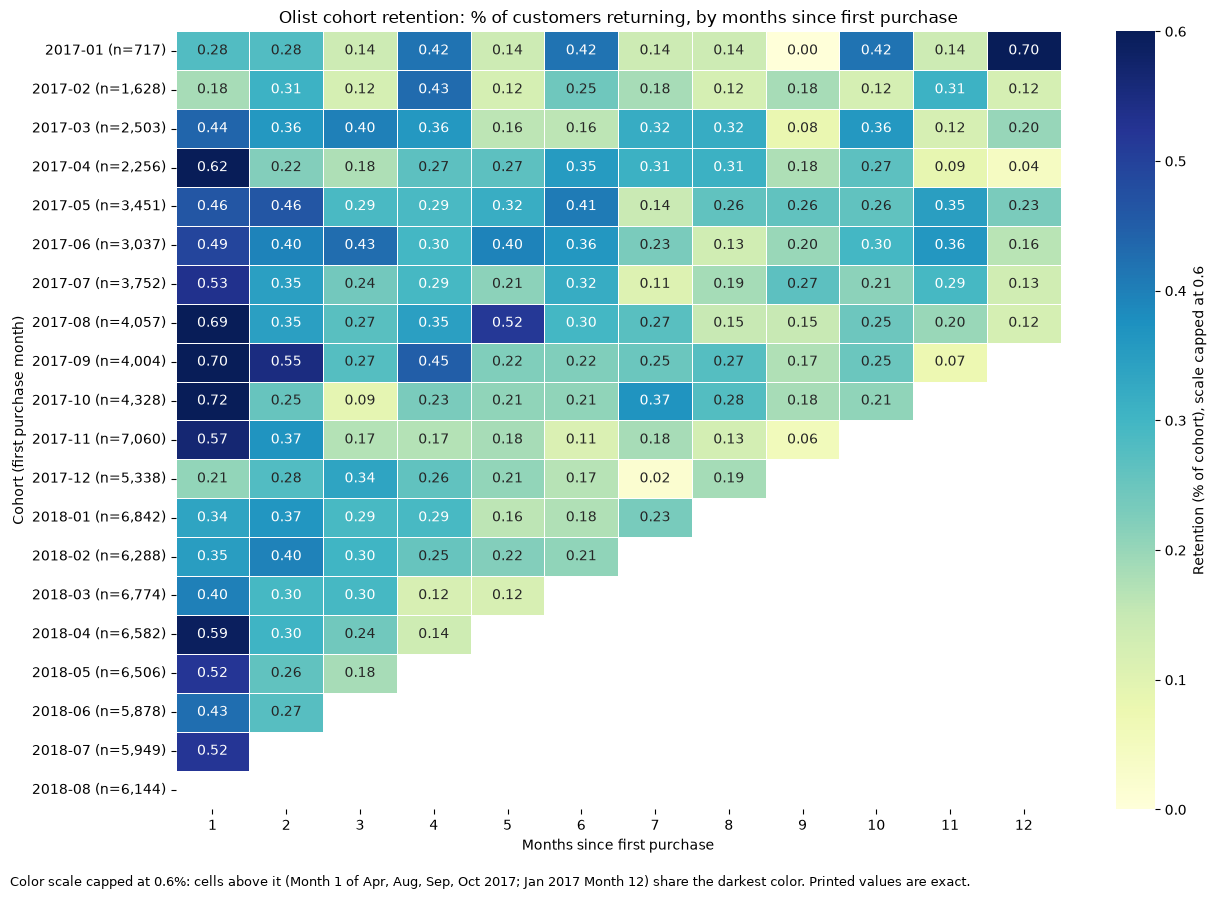

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

heat = retention_sql.iloc[:, 1:13].copy()
heat.index = [f"{c} (n={int(cohort_size[c]):,})" for c in heat.index]

fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=0.6,
            linewidths=0.5, cbar_kws={"label": "Retention (% of cohort), scale capped at 0.6"}, ax=ax)
ax.set_title("Olist cohort retention: % of customers returning, by months since first purchase")
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cohort (first purchase month)")
fig.text(0.01, 0.01, "Color scale capped at 0.6%: cells above it (Month 1 of Apr, Aug, Sep, Oct 2017; Jan 2017 Month 12) share the darkest color. Printed values are exact.", fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "cohort_retention_heatmap.png", dpi=200)
plt.show()

### Findings from the heatmap
- Retention is highest in **Month 1** and falls off in later months. By Months 8 to 12 most cells are 0.1% to 0.3%.
- The highest Month 1 values belong to the **Aug to Oct 2017 cohorts (0.69%, 0.70%, 0.72%)**, whose return month fell near Black Friday. Apr 2017 (0.62%) is also above the color cap.
- No cell exceeds 0.72% except Jan 2017 Month 12 (0.70%, about 5 customers), which is noise.
- The final calendar diagonal (Aug 2018) is likely understated because undelivered Aug 2018 orders are excluded.
- **Answer to the CEO's question:** 2017 customers are still buying in 2018, but only in tiny numbers. In any month after their first purchase, fewer than 1 in 100 of them return.

## 5. Bonus: Power Users (top 1% of customers by revenue)
- Revenue per customer = sum of `total_payment_value` over **delivered** orders, queried from the star schema.
- Power Users = customers at or above the 99th percentile of revenue.
- Questions: how much revenue do they generate, are they repeat buyers or one-time big spenders, and where are they?

In [5]:
query = """
SELECT c.customer_key, c.customer_unique_id, c.state,
       COUNT(o.order_id)                    AS orders,
       SUM(o.total_payment_value)           AS revenue
FROM fact_orders o
JOIN dim_customers c ON o.customer_key = c.customer_key
WHERE o.order_status = 'delivered'
GROUP BY c.customer_key;
"""
with sqlite3.connect(DB_PATH) as con:
    cust = pd.read_sql(query, con)

cutoff = cust.revenue.quantile(0.99)
power = cust[cust.revenue >= cutoff]

print("Customers with delivered orders:", len(cust))
print("Power Users:", len(power), "| revenue cutoff (BRL):", round(cutoff, 2))
print("Share of total revenue from Power Users (%):", round(power.revenue.sum() / cust.revenue.sum() * 100, 1))
print("Repeat buyers: Power Users (%):", round((power.orders > 1).mean() * 100, 1),
      "| all customers (%):", round((cust.orders > 1).mean() * 100, 1))
print("Average revenue per customer (BRL): Power Users:", round(power.revenue.mean(), 2),
      "| all:", round(cust.revenue.mean(), 2), "\n")
print(power.state.value_counts().head(5))

Customers with delivered orders: 93358
Power Users: 934 | revenue cutoff (BRL): 1097.06
Share of total revenue from Power Users (%): 10.3
Repeat buyers: Power Users (%): 7.2 | all customers (%): 3.0
Average revenue per customer (BRL): Power Users: 1708.97 | all: 165.2 

state
SP    295
RJ    123
MG    104
PR     55
RS     51
Name: count, dtype: int64


### Findings from the Power Users analysis
- **934 Power Users** (top 1% of 93,358 customers) spent at least **BRL 1,097** on delivered orders. Spend includes freight.
- They generate **10.3% of revenue** and spend about **10x the average customer** (BRL 1,709 vs BRL 165). Revenue is concentrated but far from an 80/20 pattern.
- Only **7.2%** of Power Users are repeat buyers (vs 3.0% of all customers). **Most of Olist's highest-value customers buy once and never return.**
- SP, RJ and MG hold 56% of Power Users, but this largely reflects where customers live (see the state comparison).

In [6]:
share = pd.DataFrame({
    "all_customers_%":  cust.state.value_counts(normalize=True) * 100,
    "power_users_%":    power.state.value_counts(normalize=True) * 100,
}).round(1)
share["ratio"] = (share["power_users_%"] / share["all_customers_%"]).round(2)
print(share.sort_values("all_customers_%", ascending=False).head(8))

       all_customers_%  power_users_%  ratio
state                                       
SP                41.9           31.6   0.75
RJ                12.8           13.2   1.03
MG                11.8           11.1   0.94
RS                 5.5            5.5   1.00
PR                 5.1            5.9   1.16
SC                 3.7            3.9   1.05
BA                 3.4            4.8   1.41
DF                 2.2            2.1   0.95


### Findings from the state comparison
- Power Users are spread across the country. **SP is under-represented** (41.9% of customers, 31.6% of Power Users, ratio 0.75). RJ, MG, RS, SC and DF are within about 5% of their customer share.
- **BA (ratio 1.41) and PR (1.16)** are over-represented. BA rests on about 45 customers, so treat it as suggestive. Because spend includes freight, shipping costs in distant states could explain part of it (not tested).

## 6. Bonus: Delivery Time vs Review Score
Question: does slower delivery lead to worse reviews?
- Population: **delivered** orders that have a delivery time and a review, with one score per order from `v_order_review`.
- Metrics: median delivery days, mean review score, and the share of negative reviews (1 or 2 stars), since scores are polarized.
- Step 1: load the data and compare on-time vs late deliveries.

In [7]:
query = """
SELECT o.order_id, c.state, o.delivery_days, o.delay_days, r.review_score
FROM fact_orders o
JOIN dim_customers c ON o.customer_key = c.customer_key
JOIN v_order_review r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered' AND o.delivery_days IS NOT NULL;
"""
with sqlite3.connect(DB_PATH) as con:
    dr = pd.read_sql(query, con)

print("Orders analyzed:", len(dr))
print("Median delivery days:", round(dr.delivery_days.median(), 1))
print("Mean score:", round(dr.review_score.mean(), 2),
      "| negative (1-2 stars) %:", round((dr.review_score <= 2).mean() * 100, 1), "\n")

dr["late"] = dr.delay_days > 0
print(dr.groupby("late").agg(
    orders=("order_id", "count"),
    median_days=("delivery_days", "median"),
    mean_score=("review_score", "mean"),
    negative_pct=("review_score", lambda s: (s <= 2).mean() * 100),
).round(2))

Orders analyzed: 95824
Median delivery days: 10.2
Mean score: 4.16 | negative (1-2 stars) %: 12.8 

       orders  median_days  mean_score  negative_pct
late                                                
False   89443         9.80        4.29          9.27
True     6381        31.18        2.27         62.42


### Findings: on-time vs late deliveries
- **95,824 delivered orders** analyzed (99.3% of delivered orders with a delivery time have a review). Median delivery time 10.2 days, mean score 4.16, **12.8%** of reviews negative (1 or 2 stars).
- **On-time orders** (89,443): mean score **4.29**, 9.3% negative. **Late orders** (6,381, i.e. 6.7%): mean score **2.27**, **62.4%** negative, a gap of about 2 stars.
- Late orders account for roughly **a third of all negative reviews**, so about two-thirds come from on-time orders: lateness is not the only driver of poor reviews.
- Late orders are also much slower (median 31.2 vs 9.8 days), so lateness and long delivery time are intertwined. This is an association, not proof of cause.

**Step 2: slow vs late.** Group orders into delivery-time bands and compare on-time and late orders *within* the same band. If late orders score worse than on-time orders in the same band, the broken promise matters beyond the wait itself. Spearman rank correlations summarize the overall relationships.

In [8]:
bins   = [0, 7, 14, 21, 30, float("inf")]
labels = ["0-7", "7-14", "14-21", "21-30", "30+"]
dr["time_band"] = pd.cut(dr.delivery_days, bins=bins, labels=labels)

def summarize(g):
    return g.agg(
        orders=("order_id", "count"),
        mean_score=("review_score", "mean"),
        negative_pct=("review_score", lambda s: (s <= 2).mean() * 100),
    ).round(2)

print(summarize(dr.groupby("time_band", observed=True)), "\n")
print(summarize(dr.groupby(["time_band", "late"], observed=True)), "\n")
print(dr[["delivery_days", "delay_days", "review_score"]].corr(method="spearman").round(3))

           orders  mean_score  negative_pct
time_band                                  
0-7         25986        4.42          7.45
7-14        39974        4.31          8.96
14-21       17566        4.14         11.69
21-30        7870        3.61         24.28
30+          4428        2.25         63.01 

                 orders  mean_score  negative_pct
time_band late                                   
0-7       False   25927        4.42          7.44
          True       59        4.00         11.86
7-14      False   39662        4.32          8.77
          True      312        3.34         32.69
14-21     False   17039        4.18         10.72
          True      527        2.91         43.26
21-30     False    5862        3.96         14.45
          True     2008        2.59         52.99
30+       False     953        3.67         21.83
          True     3475        1.86         74.30 

               delivery_days  delay_days  review_score
delivery_days          1.000     

### Findings: slow vs late
- **Wait time is a cliff, not a line.** Mean score slips gently up to 21 days (4.42 to 4.14), then falls sharply: 3.61 at 21-30 days and **2.25 at 30+ days (63% negative)**.
- **Within every delivery-time band, late orders score far worse** than on-time orders (e.g. 14-21 days: 2.91 vs 4.18; 30+ days: 1.86 vs 3.67). The gap widens with the wait.
- **Missing the promised date hurts more than waiting:** a late order delivered in 7-14 days (3.34) scores below an on-time order that took 30+ days (3.67).
- 78% of orders in the 30+ band are late, so the cliff is mostly a lateness effect.
- Spearman: `delivery_days` vs score = -0.235, `delay_days` vs score = -0.176. The lateness effect is a step at zero, which rank correlation understates. Both are weak to moderate, so delivery explains only part of review variation.
- Caveats: the 0-7 late group has only 59 orders; findings are associations, not proof of cause.

**Step 3: by state.** Average delivery time, mean review score and share of late deliveries per customer state. States with fewer than 100 analyzed orders are excluded because their averages are unstable. Spearman correlations are computed across states.

In [9]:
by_state = dr.groupby("state").agg(
    orders=("order_id", "count"),
    avg_delivery_days=("delivery_days", "mean"),
    median_delivery_days=("delivery_days", "median"),
    mean_score=("review_score", "mean"),
    late_pct=("late", lambda s: s.mean() * 100),
).round(2)

big = by_state[by_state.orders >= 100]
print("States:", len(by_state), "| with 100+ orders:", len(big), "\n")
print(big.sort_values("avg_delivery_days").to_string(), "\n")
print("Spearman, avg delivery days vs mean score:",
      round(big.avg_delivery_days.corr(big.mean_score, method="spearman"), 3))
print("Spearman, late % vs mean score:",
      round(big.late_pct.corr(big.mean_score, method="spearman"), 3))

States: 27 | with 100+ orders: 24 

       orders  avg_delivery_days  median_delivery_days  mean_score  late_pct
state                                                                       
SP      40271               8.75                  7.21        4.25      4.43
PR       4898              11.97                 10.42        4.24      3.96
MG      11282              11.98                 10.31        4.19      4.49
DF       2067              12.95                 11.36        4.13      5.61
SC       3520              14.87                 12.98        4.13      8.07
RJ      12212              15.24                 12.03        3.97     11.93
RS       5326              15.28                 13.18        4.18      6.03
GO       1945              15.55                 13.92        4.11      6.32
ES       1970              15.62                 13.60        4.08     10.41
MS        698              15.62                 13.94        4.16      9.74
TO        273              17.68        

### Findings: by state
- 24 of 27 states have 100+ analyzed orders. **SP is fastest** (8.75 days average, 42% of orders); the slowest are AM (26.4), AL (24.5) and PA (23.6).
- Across states, average delivery days correlates with mean review score at **-0.578**, and late-delivery share correlates at **-0.904** (Spearman, n = 24). Order-level correlation was weaker (-0.235) because averaging removes order-level noise.
- **Lateness matters more than the wait itself:** AM and RO have long deliveries but rarely late orders (about 3%) and review scores like SP's. RJ and RS have the same average delivery time (about 15.3 days), but RJ is late twice as often (11.9% vs 6.0%) and scores 0.21 stars lower.
- Caveats: state averages include late orders, so the state-level correlation partly restates the order-level result. 24 states is a small sample, and AM/RO rest on 144 and 243 orders. Associations, not proof of cause.

**Chart.** Mean review score by delivery-time band, on-time vs late. Groups under 100 orders are hidden (late orders delivered in 0-7 days: 59).

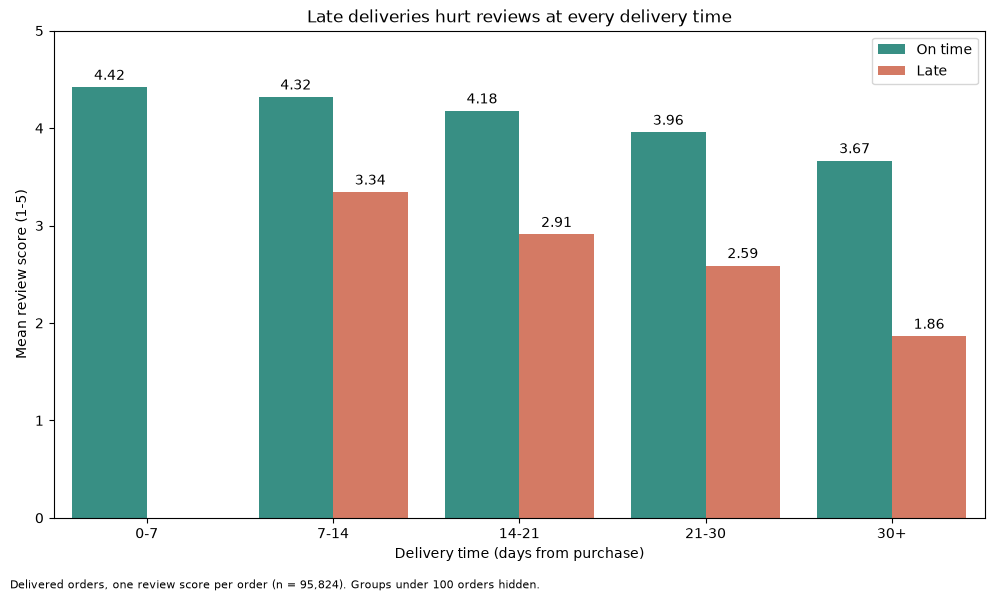

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = (dr.groupby(["time_band", "late"], observed=True)
             .agg(orders=("order_id", "count"), mean_score=("review_score", "mean"))
             .reset_index())
plot_df = plot_df[plot_df.orders >= 100]
plot_df["delivery"] = plot_df.late.map({False: "On time", True: "Late"})

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=plot_df, x="time_band", y="mean_score", hue="delivery",
            hue_order=["On time", "Late"], palette=["#2a9d8f", "#e76f51"],
            errorbar=None, ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.2f}" if v == v else "" for v in c.datavalues], padding=3)
ax.set_ylim(0, 5)
ax.set_title("Late deliveries hurt reviews at every delivery time")
ax.set_xlabel("Delivery time (days from purchase)")
ax.set_ylabel("Mean review score (1-5)")
ax.legend(title="")
fig.text(0.01, 0.01, "Delivered orders, one review score per order (n = 95,824). Groups under 100 orders hidden.", fontsize=8)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(OUTPUT_DIR / "delivery_vs_review_score.png", dpi=200)
plt.show()

## 7. Answer to the CEO's Question
**Are customers acquired in 2017 still buying in 2018?**
- Of all customers whose first delivered order was in 2017, how many placed at least one delivered order in 2018 (Jan to Aug)?
- Of all delivered orders in 2018, what share came from customers acquired in each year?

In [12]:
c2017 = df[df.cohort_month.str.startswith("2017")]
n_2017 = c2017.customer_unique_id.nunique()
n_back = c2017[c2017.year == 2018].customer_unique_id.nunique()
print("Customers acquired in 2017:", n_2017)
print("...of whom bought again in 2018:", n_back, f"({n_back / n_2017 * 100:.2f}%)\n")

orders_2018 = df[df.year == 2018]
by_acq_year = orders_2018.cohort_month.str[:4].value_counts().sort_index()
print("Delivered orders in 2018 (Jan-Aug):", len(orders_2018))
print(pd.DataFrame({"orders": by_acq_year,
                    "share_%": (by_acq_year / len(orders_2018) * 100).round(1)}))

Customers acquired in 2017: 42131
...of whom bought again in 2018: 643 (1.53%)

Delivered orders in 2018 (Jan-Aug): 52783
              orders  share_%
cohort_month                 
2016               6      0.0
2017             715      1.4
2018           52062     98.6


In [13]:
new_2018 = df[df.cohort_month.str.startswith("2018")].customer_unique_id.nunique()
print("Customers acquired in 2018:", new_2018,
      "| first orders as % of 2018 orders:", round(new_2018 / len(orders_2018) * 100, 1))

Customers acquired in 2018: 50963 | first orders as % of 2018 orders: 96.6


### Answer to the CEO's question
- **Barely.** Of **42,131** customers acquired in 2017, only **643 (1.53%)** placed another delivered order in Jan to Aug 2018.
- Customers acquired in 2017 generated just **715 of 52,783 delivered orders (1.4%)** in 2018. About **96.6%** of 2018 orders were a customer's first-ever delivered order.
- Order volume held at 6,000 to 7,000 a month through 2018, so growth came almost entirely from acquiring new customers, not from retaining existing ones.
- Limits: 2018 covers Jan to Aug only, only delivered orders are counted, and a customer is identified by `customer_unique_id`.